# Лабораторная работа №1. Регрессия Wine Quality

**Цель:** предсказать оценку `quality` по 11 химическим показателям и цвету вина.
Источник — Wine Quality, UCI (Cortez et al., 2009). `quality` — целочисленная дегустационная оценка,
по шкале 0–10 (в этой таблице 3–9),
задача решается как регрессия: прогноз может быть дробным.

Основная метрика — **RMSE**, дополнительная — **MAE**; меньше — лучше.
Порог задания — **RMSE < 0,70 на скрытой выборке**. Здесь оцениваем модели на своём фиксированном тесте.

### Подготовка

Все ячейки выполняются сверху вниз. Преобразования и модели обучаются только на train.

In [44]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, PolynomialFeatures, StandardScaler

from src.data import (
    NUMERIC_FEATURES, FEATURE_COLUMNS, LABELS, COLOR_LABELS,
    validate_data, make_group_ids, diagnose_largest_errors,
)
from src import plots
from src.results import save_results

%matplotlib inline
plots.set_style()
pd.set_option('display.notebook_repr_html', False)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 14)
pd.set_option('display.width', 150)
set_config(display='text')

ROOT = Path.cwd()
DATA = ROOT / 'wine+quality'
RESULTS = ROOT / 'results'
if not DATA.is_dir():
    raise FileNotFoundError('Запустите Jupyter из корня проекта, рядом с lab01.ipynb.')
RANDOM_STATE = 42
MODEL_LABELS = {
    'baseline': 'Baseline (среднее)', 'ordinary': 'Обычная регрессия',
    'selected': 'Улучшенная регрессия',
    'forest': 'Random Forest', 'boosting': 'Gradient Boosting',
}

## 1. Данные и первичный анализ

Объединяем красные и белые вина, добавляя `color`. Цель — `quality`, остальные 12 столбцов — признаки.
Проверяем структуру, пропуски, диапазоны и повторы.

In [45]:
red = pd.read_csv(DATA / 'winequality-red.csv', sep=';')
white = pd.read_csv(DATA / 'winequality-white.csv', sep=';')
assert list(red.columns) == list(white.columns)
wines = pd.concat([red.assign(color='red'), white.assign(color='white')], ignore_index=True)
validate_data(wines)

# Объединение должно совпасть с сохранённой таблицей.
saved_wines = pd.read_csv(DATA / 'winequality.csv', sep=';')
pd.testing.assert_frame_equal(wines, saved_wines, check_exact=False, rtol=0, atol=1e-12)
print(f'Всего {len(wines)} строк, {wines.shape[1]} столбцов.')
display(wines.head())

Всего 6497 строк, 13 столбцов.


   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0            7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978  3.51       0.56   
1            7.8              0.88         0.00             2.6      0.098                 25.0                  67.0   0.9968  3.20       0.68   
2            7.8              0.76         0.04             2.3      0.092                 15.0                  54.0   0.9970  3.26       0.65   
3           11.2              0.28         0.56             1.9      0.075                 17.0                  60.0   0.9980  3.16       0.58   
4            7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality color  
0      9.4        5   red  
1      9.8        5   red  
2      9.8        5   red  
3    

In [46]:
summary = pd.DataFrame({
    'тип': wines.dtypes.astype(str),
    'пропуски': wines.isna().sum(),
    'минимум': wines.drop(columns='color').min(),
    'медиана': wines.drop(columns='color').median(),
    'максимум': wines.drop(columns='color').max(),
}).reindex(wines.columns)
display(summary)
print('Полных повторов сверх первого экземпляра:', wines.duplicated().sum())
color_counts = wines.color.value_counts().reindex(['red', 'white'])
display(pd.DataFrame({'строк': color_counts, 'доля, %': color_counts / len(wines) * 100}).round(2))

                          тип  пропуски  минимум    медиана   максимум
fixed acidity         float64         0  3.80000    7.00000   15.90000
volatile acidity      float64         0  0.08000    0.29000    1.58000
citric acid           float64         0  0.00000    0.31000    1.66000
residual sugar        float64         0  0.60000    3.00000   65.80000
chlorides             float64         0  0.00900    0.04700    0.61100
free sulfur dioxide   float64         0  1.00000   29.00000  289.00000
total sulfur dioxide  float64         0  6.00000  118.00000  440.00000
density               float64         0  0.98711    0.99489    1.03898
pH                    float64         0  2.72000    3.21000    4.01000
sulphates             float64         0  0.22000    0.51000    2.00000
alcohol               float64         0  8.00000   10.30000   14.90000
quality                 int64         0  3.00000    6.00000    9.00000
color                     str         0      NaN        NaN        NaN

Полных повторов сверх первого экземпляра: 1177


       строк  доля, %
color                
red     1599    24.61
white   4898    75.39

**Вывод.** 6497 вин, пропусков нет. Белых 4898, красных 1599, поэтому общие результаты сильнее отражают белые вина.
1177 строк — полные повторы. Их и крайние значения сохраняем: редкость сама по себе не доказывает ошибку.
Для проверки качества копии измерений далее попадут целиком в одну часть выборки.

### Распределения

Гистограммы показывают частоты значений; для quality и цвета используются столбцы. Диапазоны не обрезаны.

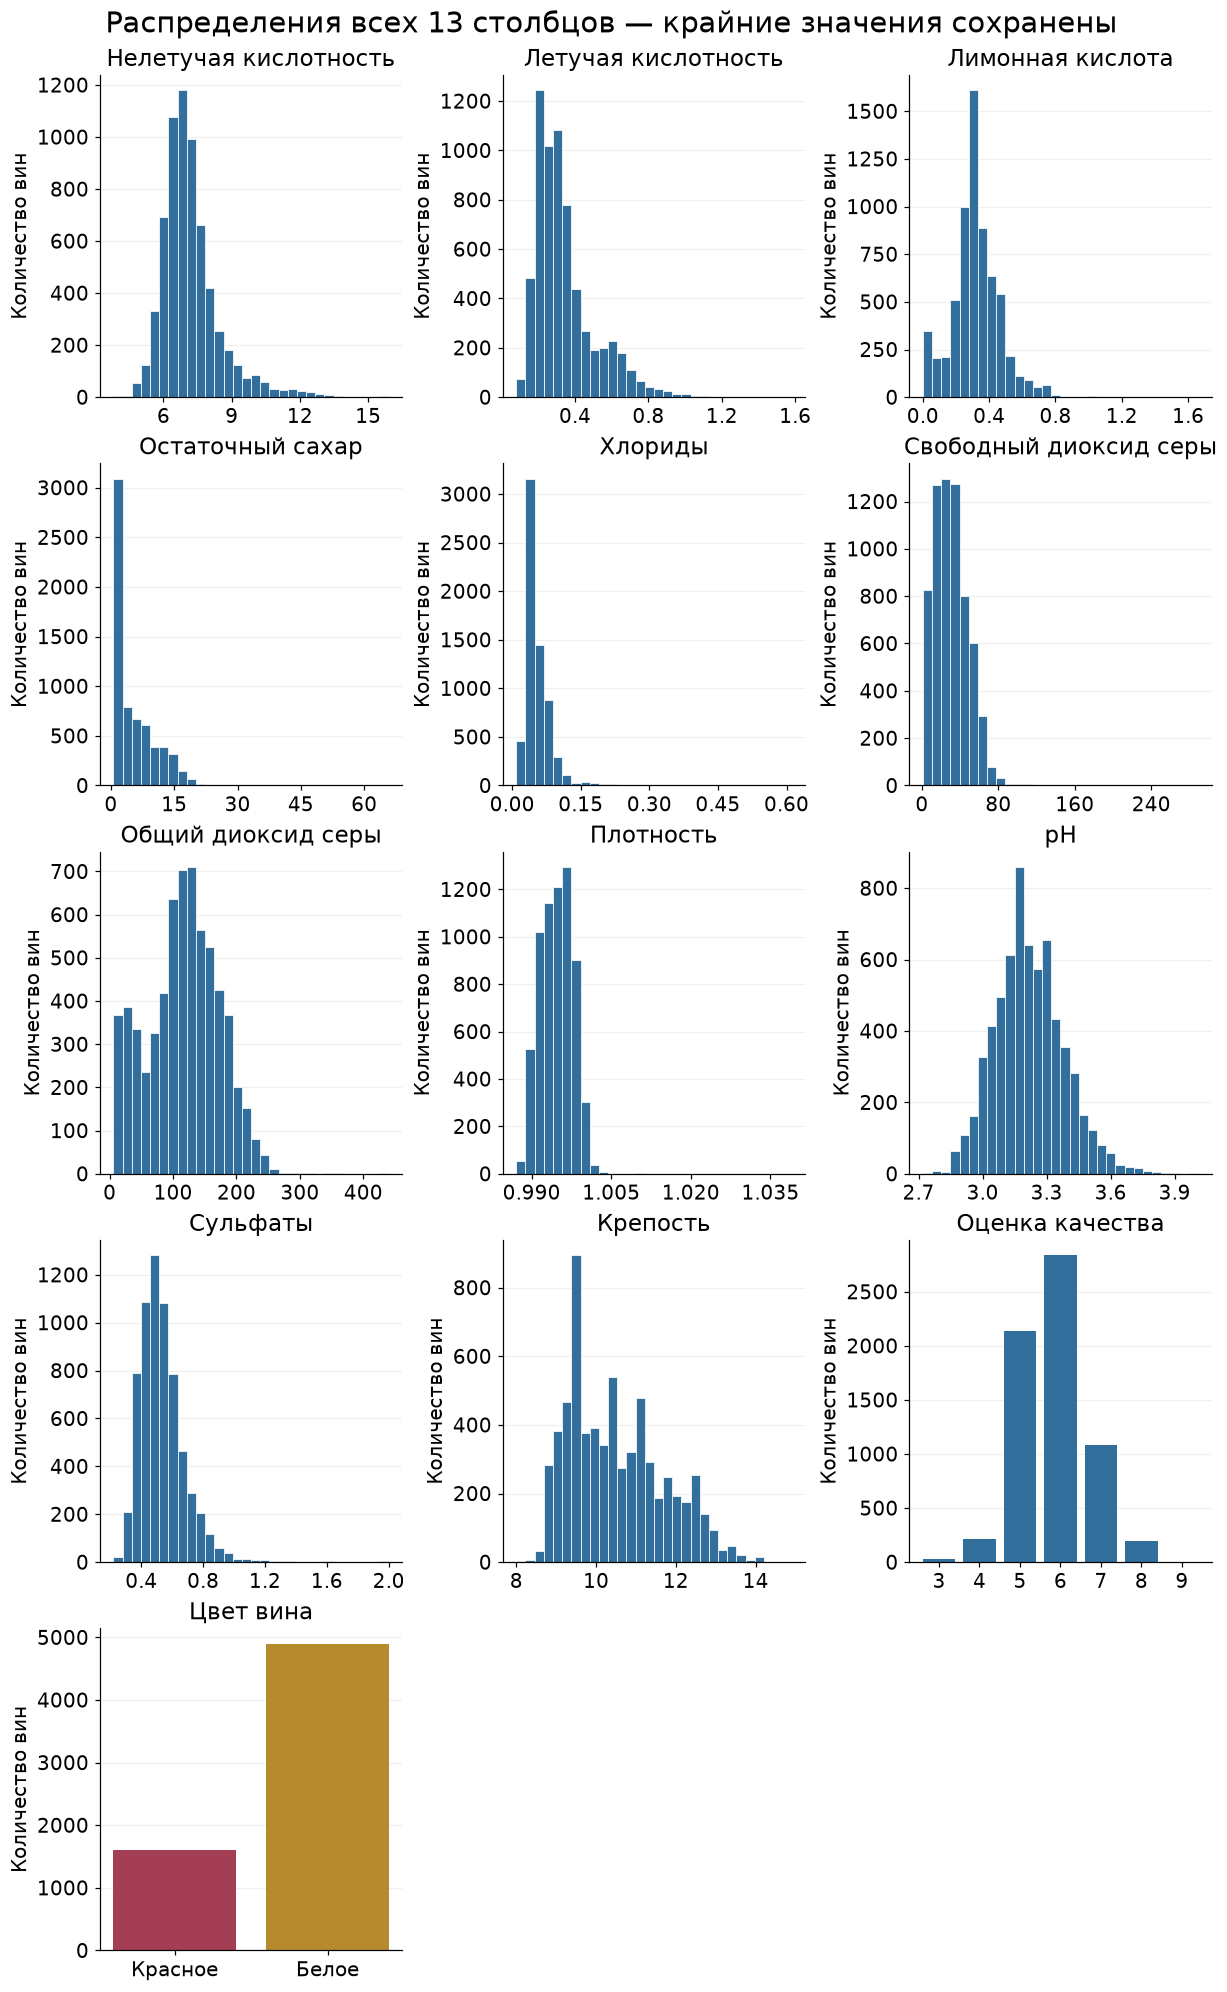

In [47]:
plots.distributions(wines)
plt.show()

**Вывод.** Большинство оценок — 5–6, оценки 3, 8 и 9 редкие: модель может хуже учиться на них.
У сахара и SO₂ длинные правые хвосты; сахар достигает 65,8, плотность — 1,03898.
Крайние значения подтверждены исходными CSV. В анализе ошибок отдельно посмотрим на необычные вина.

### Связи с quality и между признаками

Корреляция Пирсона показывает направление и силу **линейной** связи.
Сравниваем все вина и каждый цвет отдельно, чтобы общая связь не скрывала различия групп.

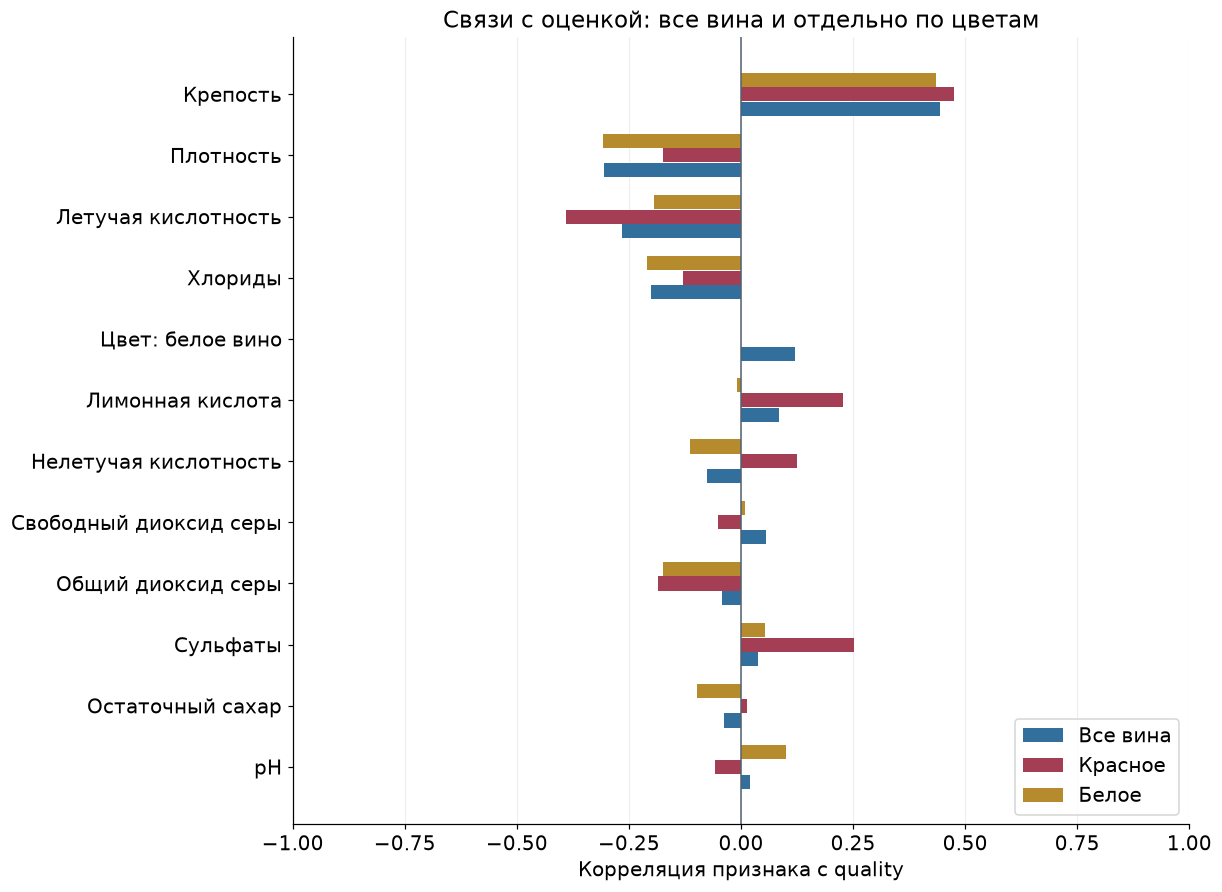

In [48]:
numeric_all = wines[NUMERIC_FEATURES].assign(
    color_white=(wines.color == 'white').astype(int), quality=wines.quality
)
matrices = {'Все вина': numeric_all.corr()}
for color, label in COLOR_LABELS.items():
    matrices[label] = wines.loc[wines.color == color, [*NUMERIC_FEATURES, 'quality']].corr()
target_correlations = pd.DataFrame({
    label: matrix['quality'].drop('quality') for label, matrix in matrices.items()
})
plots.target_correlations(target_correlations)
plt.show()

**Вывод.** Более крепкие вина чаще получают высокую оценку. У плотности, летучей кислотности и хлоридов
общая связь с quality отрицательная. Связи различаются по цветам; слабая парная корреляция не исключает
полезность признака в сочетании с другими. Поэтому используем все признаки и учитываем цвет.

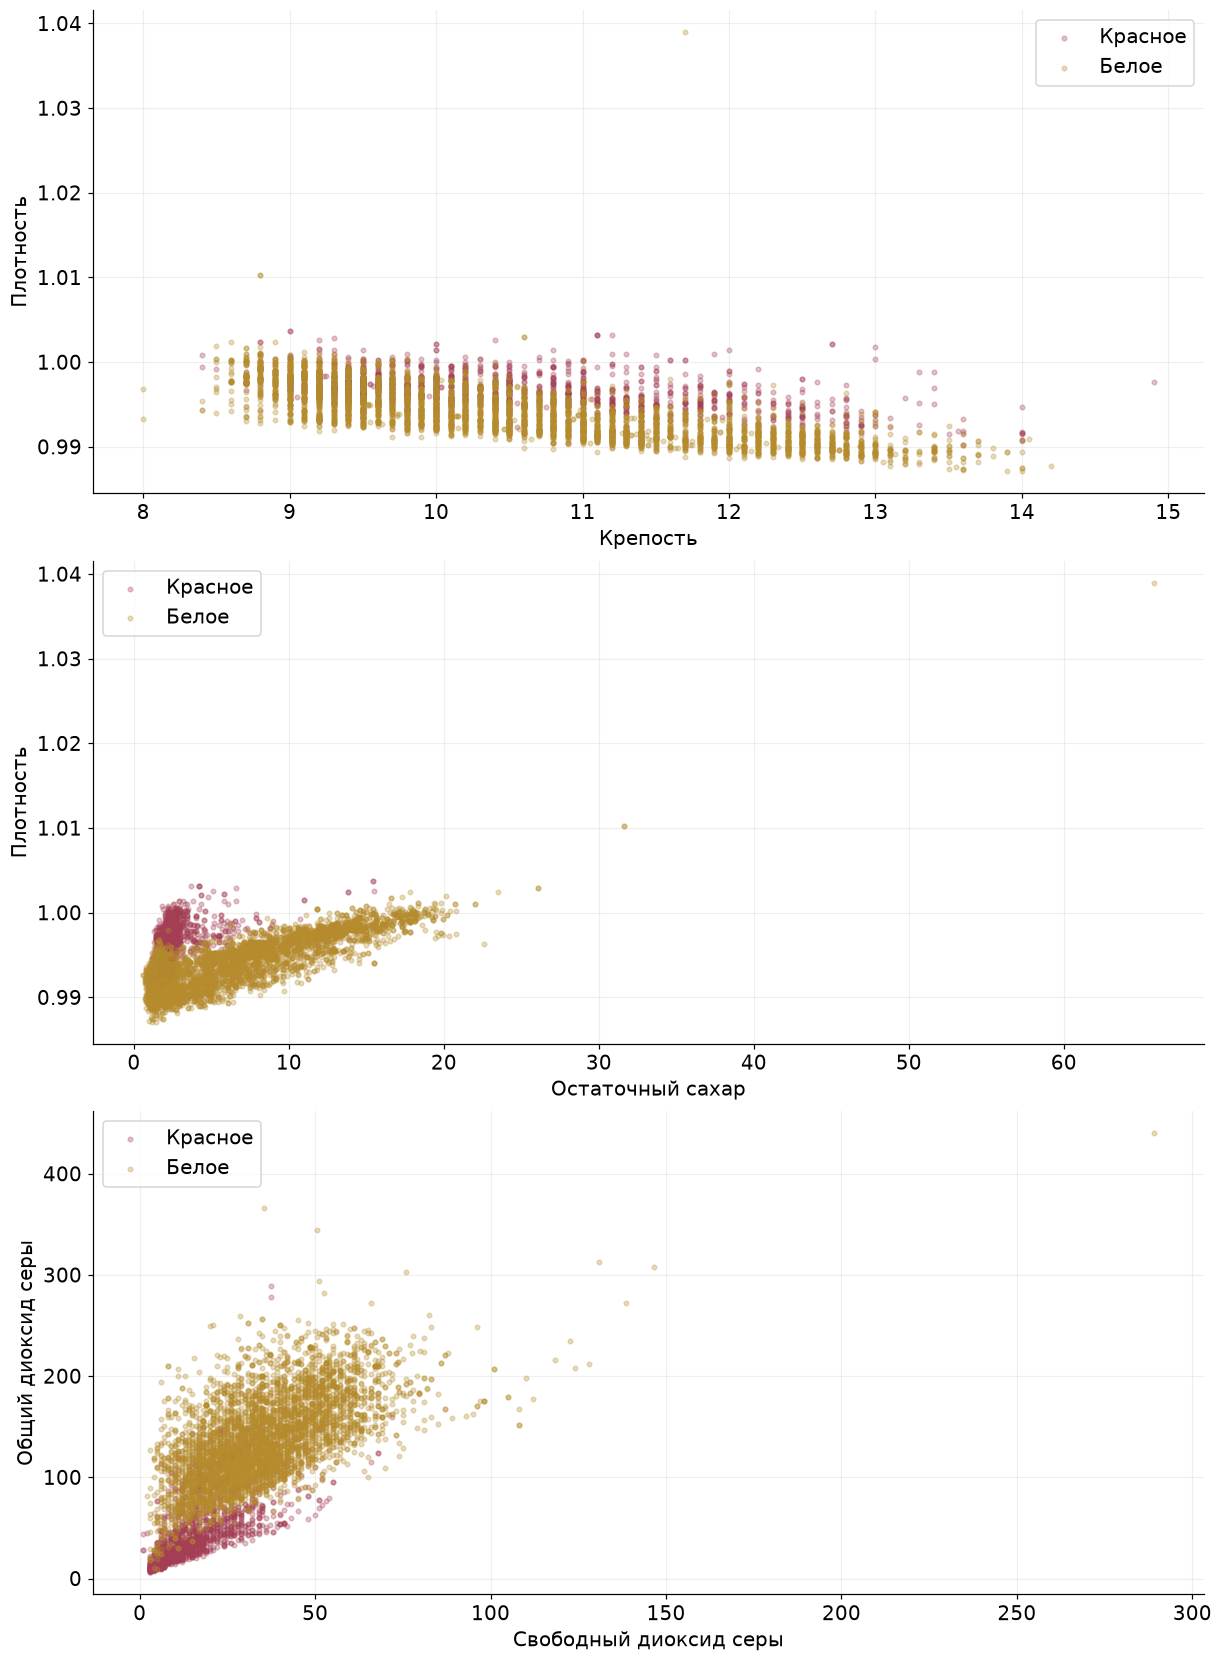

         Медиана сахара  Медиана общего SO₂  Сахар > 10, %
color                                                     
Красное             2.2                38.0           0.69
Белое               5.2               134.0          24.36

In [49]:
plots.scatter_pairs(wines)
plt.show()
color_summary = wines.groupby('color')[['residual sugar', 'total sulfur dioxide']].median()
color_summary.columns = ['Медиана сахара', 'Медиана общего SO₂']
color_summary['Сахар > 10, %'] = wines.groupby('color')['residual sugar'].apply(
    lambda values: (values > 10).mean() * 100
)
display(color_summary.rename(index=COLOR_LABELS).round(2))

**Вывод.** Крепость и плотность связаны обратно, сахар и плотность — положительно.
Свободный и общий SO₂ тоже связаны. Белые вина чаще содержат много сахара и обычно больше общего SO₂.
Связанные признаки частично несут общую информацию: это важно при интерпретации весов регрессии.
Наблюдаемые связи не доказывают причинность.

## 2. Разбиение данных

**80% групп — train, 20% — test; random_state=42.** Это компромисс между объёмом обучения и проверки;
фиксированный seed позволяет повторить разбиение.
Группа — одинаковые 11 химических показателей и цвет, **без quality**. Она целиком попадает в одну часть,
чтобы модель не получила копию тестового вина в обучении.

In [50]:
groups = make_group_ids(wines)
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_indices, test_indices = next(splitter.split(wines, groups=groups))
calculated_train = wines.iloc[train_indices].reset_index(drop=True)
calculated_test = wines.iloc[test_indices].reset_index(drop=True)

train = pd.read_csv(DATA / 'splits/train.csv', sep=';')
test = pd.read_csv(DATA / 'splits/test.csv', sep=';')
for calculated, saved in [(calculated_train, train), (calculated_test, test)]:
    validate_data(saved)
    pd.testing.assert_frame_equal(calculated, saved, check_exact=False, rtol=0, atol=1e-12)

combined_groups = make_group_ids(pd.concat([train, test], ignore_index=True))
train_groups = combined_groups.iloc[:len(train)]
test_groups = combined_groups.iloc[len(train):]
overlap = set(train_groups) & set(test_groups)
assert not overlap
split_summary = pd.DataFrame({
    'строк': [len(train), len(test)],
    'доля строк, %': [len(train) / len(wines) * 100, len(test) / len(wines) * 100],
    'групп': [train_groups.nunique(), test_groups.nunique()],
}, index=['train', 'test'])
display(split_summary.round(2))
print('Пересекающихся групп:', len(overlap))
quality_counts = pd.DataFrame({'train': train.quality.value_counts(), 'test': test.quality.value_counts()})
display(quality_counts.fillna(0).astype(int).sort_index())

X_train, X_test = train[FEATURE_COLUMNS], test[FEATURE_COLUMNS]
y_train, y_test = train.quality, test.quality

       строк  доля строк, %  групп
train   5183          79.78   4256
test    1314          20.22   1064

Пересекающихся групп: 0


         train  test
quality             
3           24     6
4          171    45
5         1730   408
6         2277   559
7          824   255
8          152    41
9            5     0

**Вывод.** Train — 5183 строки, test — 1314, общих групп нет. Доля строк чуть отличается от 20% из-за размеров групп.
Разбиение не стратифицировано: quality=9 в тесте отсутствует, её точность оценить нельзя.

**Ограничение эксперимента.** Параметры улучшенной регрессии выбирались на групповых проверках внутри train
(5 частей × 3 фиксированных seed). Однако test уже просматривался в прошлых сравнениях.
Повторный выбор по одному тесту может подстроить решения под него и завысить оценку качества.
В этом запуске настройки фиксированы; независимая скрытая проверка ещё не выполнена.

## 3. Baseline и метрики

Baseline предсказывает всем **среднюю quality по train**. Среднее минимизирует квадратичную ошибку среди констант,
поэтому подходит для RMSE. Для MAE оптимальная константа — медиана.

$$MAE = \frac{1}{n}\sum_i |\hat y_i-y_i|,\qquad
RMSE = \sqrt{\frac{1}{n}\sum_i (\hat y_i-y_i)^2}.$$

Обе метрики измеряются в баллах quality. MAE — средний размер промаха.
RMSE сильнее реагирует на большие ошибки: промах на 2 даёт 4 до извлечения корня.
Поэтому при неодинаковых промахах RMSE больше MAE. Итоговые значения всех моделей собраны в разделе 7.

In [51]:
# Общий сбор результатов; обучение остаётся явно в ячейках каждой модели.
predictions = test.copy()
predictions.insert(0, 'test_row_index', np.arange(len(test)))
metric_rows = []
models = {}

def record_result(key, forecast, train_forecast, n_features):
    forecast = np.asarray(forecast)
    error = forecast - y_test.to_numpy()
    predictions[f'prediction_{key}'] = forecast
    predictions[f'error_{key}'] = error
    metric_rows[:] = [row for row in metric_rows if row['model'] != key]
    metric_rows.append({
        'model': key, 'features': n_features,
        'rmse': float(root_mean_squared_error(y_test, forecast)),
        'mae': float(mean_absolute_error(y_test, forecast)),
        'train_rmse': float(root_mean_squared_error(y_train, train_forecast)),
        'max_abs_error': float(np.abs(error).max()),
    })

baseline_constant = float(y_train.mean())
baseline_prediction = np.full(len(test), baseline_constant)
record_result('baseline', baseline_prediction, np.full(len(train), baseline_constant), 0)
print(f'Baseline предсказывает всем: {baseline_constant:.6f}')

Baseline предсказывает всем: 5.806869


## 4. Линейная регрессия

Модель: **прогноз = свободный член + сумма «вес × признак»**.
`fit()` подбирает веса, минимизируя сумму квадратов ошибок; `predict()` использует готовые веса.
В Pipeline числовые признаки стандартизируются по train, цвет кодируется: красное = 0, белое = 1.
Масштабирование позволяет сравнивать веса химических показателей и помогает численной устойчивости.

In [52]:
def prepare_columns(numeric_transformer):
    return ColumnTransformer([
        ('numeric', numeric_transformer, NUMERIC_FEATURES),
        ('color', OneHotEncoder(categories=[['red', 'white']], drop='first',
                                sparse_output=False, handle_unknown='error'), ['color']),
    ], remainder='drop', verbose_feature_names_out=False)

ordinary = Pipeline([
    ('preprocessing', prepare_columns(StandardScaler())),
    ('regression', LinearRegression()),
])
ordinary.fit(X_train, y_train)
ordinary_prediction = ordinary.predict(X_test)
record_result('ordinary', ordinary_prediction, ordinary.predict(X_train),
              ordinary.named_steps['regression'].n_features_in_)
models['ordinary'] = ordinary

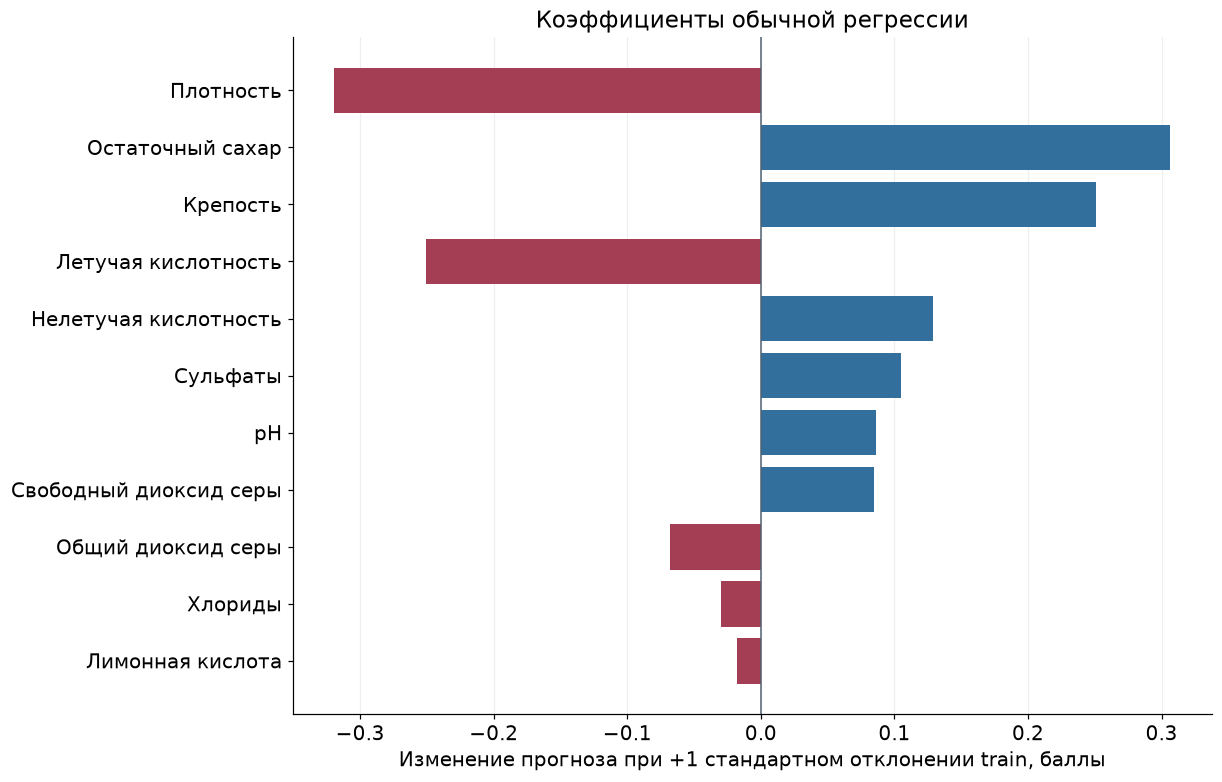

Коэффициент цвета (белое вместо красного): -0.362
Корреляция сахара с quality в train: -0.024


In [53]:
ordinary_coefficients = pd.Series(
    ordinary.named_steps['regression'].coef_,
    index=ordinary[:-1].get_feature_names_out(), name='коэффициент'
)
plots.coefficients(ordinary_coefficients)
plt.show()
print(f"Коэффициент цвета (белое вместо красного): {ordinary_coefficients['color_white']:.3f}")
print(f"Корреляция сахара с quality в train: {train['residual sugar'].corr(y_train):.3f}")

**Интерпретация.** Числовой вес — изменение прогноза при увеличении признака на одно стандартное отклонение train,
если остальные признаки фиксированы. Наиболее заметны веса плотности (−0,319), сахара (+0,306),
крепости (+0,251) и летучей кислотности (−0,250).
Вес цвета относится к переходу 0 → 1, поэтому не сравниваем его напрямую со стандартизированными показателями.

Большой вес сахара при слабой корреляции не противоречие: вес учитывает одновременно плотность и другие признаки,
а корреляция — только пару. При связанных показателях отдельные веса могут быть нестабильны и не означают причинный эффект.

### Улучшенная регрессия

Чтобы описать более сложные зависимости, добавлены:

1. `log1p` сахара и обоих SO₂ — сжатие длинных правых хвостов.
2. Квадраты и попарные произведения — нелинейность и сочетания признаков.
3. Произведения на индикатор белого вина — разные зависимости для двух цветов.
4. Ridge с `alpha=750`: штраф $\alpha\sum_j w_j^2$ ограничивает веса и снижает риск переобучения.

Чем больше alpha, тем сильнее штраф; чрезмерная регуляризация приводит к недообучению.
Настройки выбраны по внутренним проверкам train; история сохранена в `results/experiments.csv`.
После преобразований 155 признаков. Модель остаётся линейной по их весам.

In [54]:
LOG1P_FEATURES = ('residual sugar', 'free sulfur dioxide', 'total sulfur dioxide')
LOG1P_INDICES = [NUMERIC_FEATURES.index(name) for name in LOG1P_FEATURES]

def log1p_selected_numeric(values):
    result = np.array(values, dtype=float, copy=True)
    result[:, LOG1P_INDICES] = np.log1p(result[:, LOG1P_INDICES])
    return result

def log1p_feature_names(transformer, input_features):
    return np.asarray([
        f'log1p({name})' if name in LOG1P_FEATURES else name for name in input_features
    ], dtype=object)

def add_color_interactions(values):
    # Последний столбец — color_white; дописываем числовые члены × color_white.
    return np.column_stack([values, values[:, :-1] * values[:, -1:]])

def interaction_feature_names(transformer, input_features):
    return np.asarray([
        *input_features, *[f'{name}:color_white' for name in input_features[:-1]]
    ], dtype=object)

In [55]:
numeric_polynomial = Pipeline([
    ('log1p', FunctionTransformer(log1p_selected_numeric, validate=True,
                                 feature_names_out=log1p_feature_names)),
    ('scaling', StandardScaler()),
    ('polynomial', PolynomialFeatures(degree=2, include_bias=False)),
    ('expanded_scaling', StandardScaler()),
])
selected = Pipeline([
    ('preprocessing', prepare_columns(numeric_polynomial)),
    ('color_interactions', FunctionTransformer(add_color_interactions, validate=True,
                                              feature_names_out=interaction_feature_names)),
    ('regression', Ridge(alpha=750.0, solver='svd')),
])
selected.fit(X_train, y_train)
selected_prediction = selected.predict(X_test)
record_result('selected', selected_prediction, selected.predict(X_train),
              selected.named_steps['regression'].n_features_in_)
models['selected'] = selected
assert selected.named_steps['regression'].n_features_in_ == 155

**Что изменилось.** У обычной модели один постоянный вес на показатель.
У улучшенной вклад зависит также от квадратов, произведений и цвета.
Поэтому один её коэффициент уже нельзя трактовать как постоянный эффект исходного показателя.
Обе регрессии далее сравниваем на том же тесте.

## 5. Случайный лес

300 деревьев обучаются на разных bootstrap-выборках train — строки выбираются с возвращением.
Дерево делит данные условиями вида «признак ≤ порог», уменьшая квадратичную ошибку;
прогноз листа — средняя quality. Лес усредняет ответы деревьев.

`max_features=1.0` разрешает все признаки, основной источник разнообразия здесь — bootstrap.
Глубина не ограничена, минимальный лист — одна строка. Ограничение глубины или увеличение листа
упрощает модель; больше деревьев стабилизирует усреднение, но увеличивает время.
Деревьям стандартизация не требуется.

In [56]:
FOREST_PARAMS = {
    'n_estimators': 300,
    'criterion': 'squared_error',
    'max_depth': None,
    'min_samples_split': 2,
    'min_samples_leaf': 1,
    'max_features': 1.0,
    'bootstrap': True,
    'random_state': 42,
    'n_jobs': -1,
}

forest = Pipeline([
    ('preprocessing', prepare_columns('passthrough')),
    ('regression', RandomForestRegressor(**FOREST_PARAMS)),
])
forest.fit(X_train, y_train)
forest_prediction = forest.predict(X_test)
record_result('forest', forest_prediction, forest.predict(X_train),
              forest.named_steps['regression'].n_features_in_)
models['forest'] = forest

## 6. Градиентный бустинг

Начинает со средней quality и последовательно исправляет ошибки текущего прогноза.
При `squared_error` очередное дерево учится на остатках $y-\hat y$.
К прогнозу добавляется `learning_rate × ответ дерева`.

Используем 300 деревьев глубиной до 3 и `learning_rate=0.05`.
Меньший шаг обычно требует больше деревьев; чрезмерная глубина или число шагов могут вызвать переобучение.
В отличие от леса, деревья зависят от предыдущих и строятся последовательно.

In [57]:
BOOSTING_PARAMS = {
    'loss': 'squared_error',
    'n_estimators': 300,
    'learning_rate': 0.05,
    'max_depth': 3,
    'min_samples_split': 2,
    'min_samples_leaf': 1,
    'subsample': 1.0,
    'max_features': None,
    'init': None,
    'n_iter_no_change': None,
    'random_state': 42,
}

boosting = Pipeline([
    ('preprocessing', prepare_columns('passthrough')),
    ('regression', GradientBoostingRegressor(**BOOSTING_PARAMS)),
])
boosting.fit(X_train, y_train)
boosting_prediction = boosting.predict(X_test)
record_result('boosting', boosting_prediction, boosting.predict(X_train),
              boosting.named_steps['regression'].n_features_in_)
models['boosting'] = boosting

## 7. Сравнение моделей

Для всех решений одинаковые train/test и исходные признаки. Прогнозы не округляются и не обрезаются.
Настройки зафиксированы; лес и бустинг здесь не проходили подбор параметров.

In [58]:
metrics = pd.DataFrame(metric_rows).set_index('model').reindex(MODEL_LABELS)
for metric in ['rmse', 'mae']:
    metrics[f'gain_{metric}_vs_baseline'] = metrics.loc['baseline', metric] - metrics[metric]
display(metrics[['train_rmse', 'rmse', 'mae']].rename(
    index=MODEL_LABELS,
    columns={'train_rmse': 'RMSE train', 'rmse': 'RMSE test', 'mae': 'MAE test'}
).round(6))
best_key = metrics.drop(index='baseline').rmse.idxmin()

                      RMSE train  RMSE test  MAE test
model                                                
Baseline (среднее)      0.868964   0.890022  0.707367
Обычная регрессия       0.732350   0.733495  0.573858
Улучшенная регрессия    0.690317   0.695804  0.540930
Random Forest           0.217562   0.678809  0.519447
Gradient Boosting       0.613727   0.686534  0.533456

**Вывод.** Все обученные модели лучше baseline по обеим метрикам: признаки дают полезную информацию.
Обычная регрессия ограничена линейной суммой; нелинейные члены улучшили её RMSE с 0,7335 до 0,6958.
Деревья описывают пороги и сочетания показателей без явного создания произведений.

Лучший на этом тесте — **Random Forest: RMSE 0,6788, MAE 0,5194**.
Большой разрыв между train и test указывает на риск переобучения.
Преимущество над бустингом небольшое и не доказывает превосходство алгоритма вообще.
Улучшенная регрессия, лес и бустинг прошли 0,70 на нашем тесте; скрытая проверка ещё впереди.

## 8. Важности признаков

Встроенная важность — доля уменьшения квадратичной ошибки на обучающих разделениях по признаку.
Внутри каждой модели сумма равна 1. Сравним лес, бустинг, коэффициенты регрессии и корреляции по train.

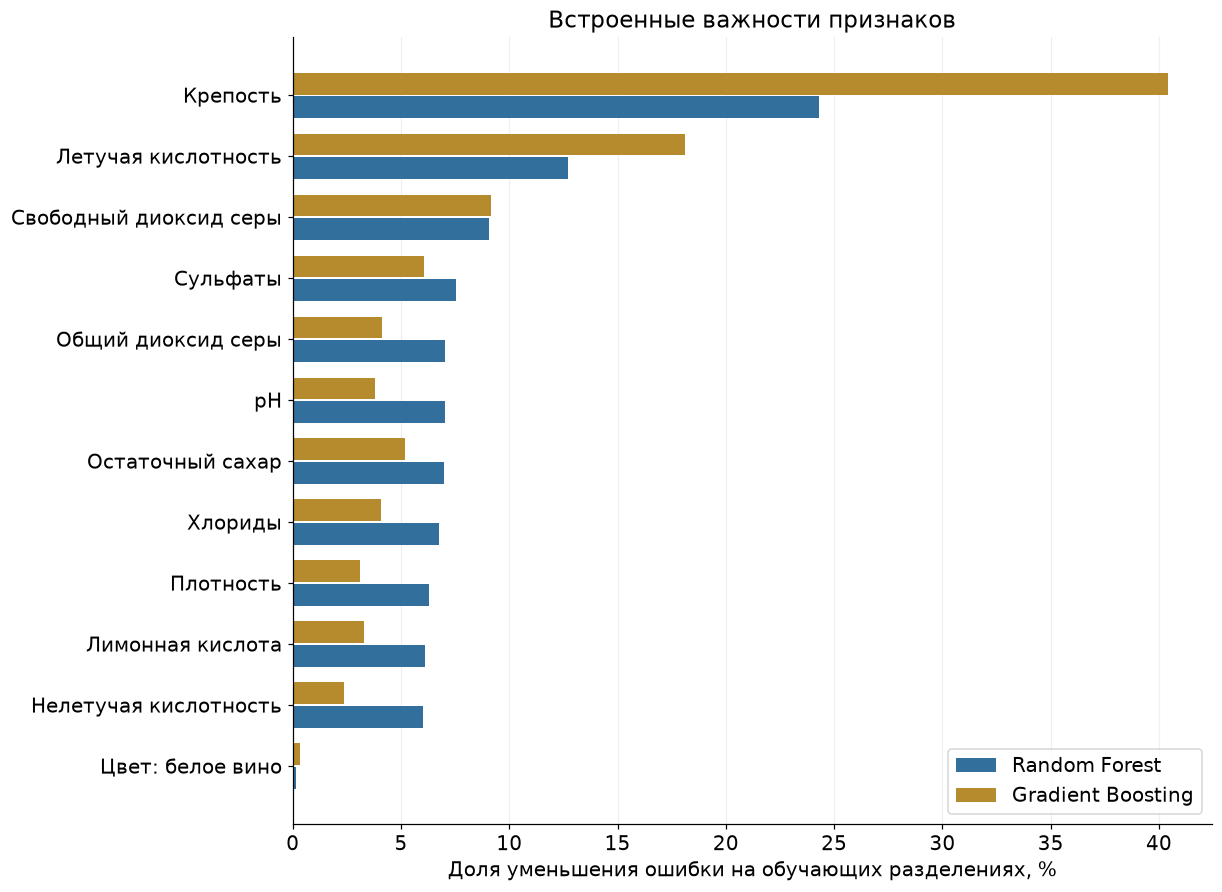

                           Лес  Бустинг  Вес регрессии  Корреляция с quality
feature                                                                     
Крепость                0.2428   0.4042         0.2512                0.4327
Летучая кислотность     0.1273   0.1811        -0.2505               -0.2723
Свободный диоксид серы  0.0908   0.0914         0.0849                0.0590
Сульфаты                0.0754   0.0607         0.1051                0.0392
Общий диоксид серы      0.0705   0.0410        -0.0683               -0.0278
pH                      0.0704   0.0380         0.0864                0.0172

In [59]:
importance = pd.DataFrame({
    key: pd.Series(models[key].named_steps['regression'].feature_importances_,
                   index=models[key].named_steps['preprocessing'].get_feature_names_out())
    for key in ['forest', 'boosting']
})
importance['ordinary_coefficient'] = ordinary_coefficients
train_numeric = train[NUMERIC_FEATURES].assign(color_white=(train.color == 'white').astype(int))
importance['train_correlation_quality'] = train_numeric.corrwith(y_train)
importance.index.name = 'feature'
plots.importances(importance)
plt.show()
display(importance.sort_values('forest', ascending=False).head(6).rename(
    index=LABELS,
    columns={'forest': 'Лес', 'boosting': 'Бустинг',
             'ordinary_coefficient': 'Вес регрессии', 'train_correlation_quality': 'Корреляция с quality'}
).round(4))

**Вывод.** У обоих ансамблей лидируют крепость, летучая кислотность и свободный SO₂.
Крепость и летучая кислотность заметны также в корреляциях и обычной регрессии.
У свободного SO₂ корреляция слабая, но деревья используют его в порогах и сочетаниях.
Плотность и сахар имеют большие веса регрессии, однако уступают этим трём по важности в ансамблях.

**Важность не устанавливает причину изменения качества.** Это наблюдательные данные;
связанные признаки делят вклад, неучтённые факторы могут влиять на оценку.
Встроенная важность также зависит от числа доступных порогов и не показывает направление эффекта.

## 9. Анализ ошибок лучшей модели

Разбираем лес. **Ошибка = прогноз − настоящая quality**: плюс — завышение, минус — занижение.
Диагональ на втором графике соответствует точному прогнозу.

Средняя подписанная ошибка: **-0.0071**. Промах не больше одного балла у **88.05%** вин. Ошибка больше двух баллов — у **15** строк. Максимальный промах: **2.9467** балла.

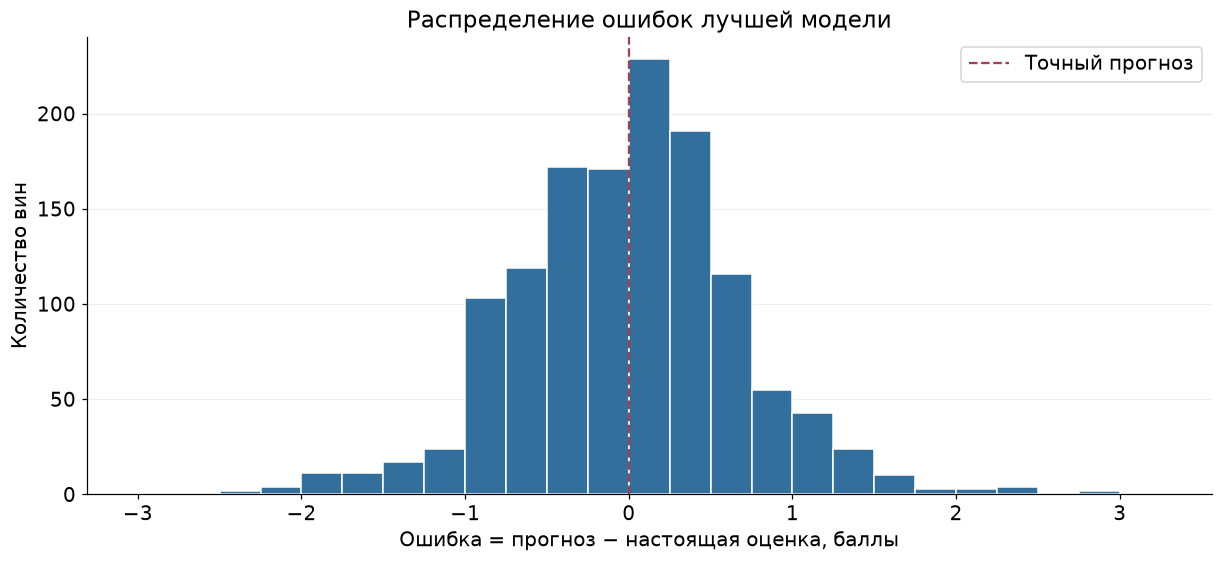

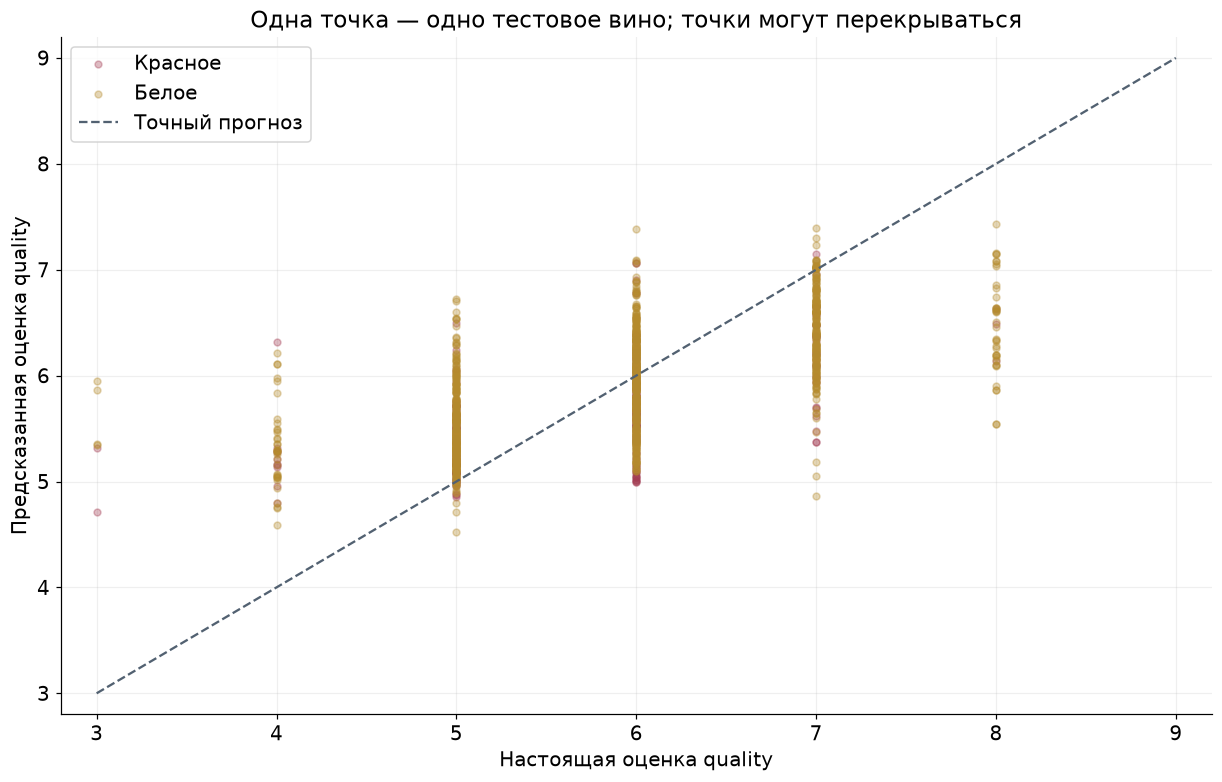

In [60]:
work = predictions.copy()
work['prediction'] = work[f'prediction_{best_key}']
work['error'] = work[f'error_{best_key}']
work['absolute_error'] = work.error.abs()
display(Markdown(f"Средняя подписанная ошибка: **{work.error.mean():+.4f}**. "
                 f"Промах не больше одного балла у **{(work.absolute_error <= 1).mean() * 100:.2f}%** вин. "
                 f"Ошибка больше двух баллов — у **{(work.absolute_error > 2).sum()}** строк. "
                 f"Максимальный промах: **{work.absolute_error.max():.4f}** балла."))
plots.error_distribution(work.error)
plt.show()

plots.actual_vs_predicted(predictions, best_key)
plt.show()

**Наблюдение.** Средняя подписанная ошибка близка к нулю, но большие промахи остаются:
завышения и занижения могут взаимно погаситься. Низкие оценки чаще завышаются, высокие — занижаются:
усреднение тянет прогнозы к распространённым 5–6.

  quality n_train n_test    rmse     mae    bias
0       3      24      6  2.4575  2.4233  2.4233
1       4     171     45  1.3731  1.3149  1.3149
2       5    1730    408  0.5857  0.4701  0.4607
3       6    2277    559  0.4412  0.3579 -0.1032
4       7     824    255  0.7208  0.6061  -0.592
5       8     152     41  1.5864  1.5222 -1.5222
6       9       5      0       —       —       —

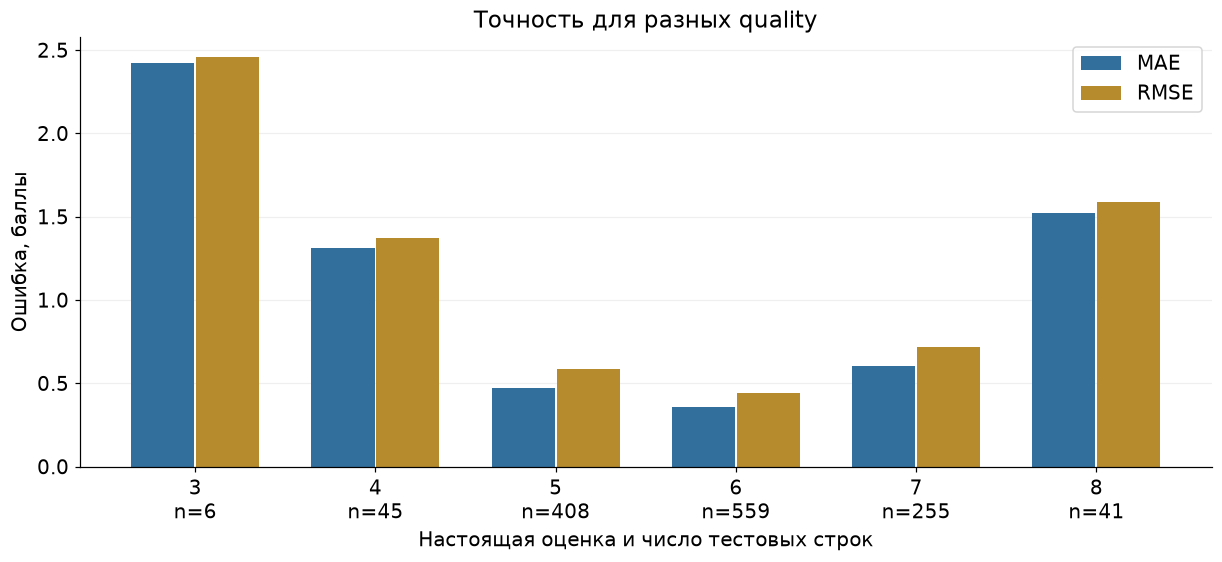

In [61]:
def error_statistics(errors):
    if errors.empty:
        return {'rmse': np.nan, 'mae': np.nan, 'bias': np.nan}
    return {'rmse': float(np.sqrt(np.mean(errors ** 2))),
            'mae': float(errors.abs().mean()), 'bias': float(errors.mean())}

quality_rows = []
for quality in sorted(set(y_train) | set(y_test)):
    errors = work.loc[work.quality == quality, 'error']
    quality_rows.append({'quality': quality, 'n_train': int((y_train == quality).sum()),
                         'n_test': len(errors), **error_statistics(errors)})
by_quality = pd.DataFrame(quality_rows)
display(by_quality.round(4).astype(object).where(by_quality.notna(), '—'))
plots.errors_by_quality(by_quality)
plt.show()

by_color = pd.DataFrame([
    {'color': color, 'n_train': int((train.color == color).sum()),
     'n_test': int((work.color == color).sum()),
     **error_statistics(work.loc[work.color == color, 'error'])}
    for color in ['red', 'white']
])

**Вывод.** При quality=3 MAE ≈ 2,42 (всего 6 тестовых строк), при quality=8 — 1,52 (41 строка),
при quality=6 — 0,36 (559 строк). Редких оценок мало в обучении, поэтому их закономерности усваиваются хуже;
метрики малых групп менее устойчивы. Для quality=9 «—» означает отсутствие проверки, а не нулевую ошибку.

### Крупные промахи

Показываем пять разных наборов измерений с наибольшей ошибкой.
Для диагностики находим пять ближайших вин train того же цвета по стандартизированным химическим показателям.
Quality в поиск соседей не входит; соседи не объясняют конкретные ветви леса.

In [62]:
largest_errors = diagnose_largest_errors(train, work, n=10)
display(largest_errors[[
    'test_row_index', 'color', 'quality', 'prediction', 'absolute_error', 'neighbor_qualities'
]].head(5).round(4))

      test_row_index  color  quality  prediction  absolute_error neighbor_qualities
943              943  white        3      5.9467          2.9467      6, 5, 5, 5, 5
1007            1007  white        3      5.8667          2.8667      6, 6, 6, 7, 7
540              540  white        8      5.5400          2.4600      7, 5, 5, 5, 4
692              692  white        3      5.3533          2.3533      5, 4, 3, 6, 6
344              344  white        3      5.3467          2.3467      4, 6, 7, 6, 4

**Три примера** (`test_row_index` — номер строки теста, начиная с 0):

- **943:** настоящая оценка 3, прогноз 5,95. У ближайших вин оценки 6, 5, 5, 5, 5;
  крайних химических показателей в пределах 1% train своего цвета нет.
  Возможное объяснение — редкая низкая оценка при химии, похожей на обычные вина.
- **540:** оценка 8, прогноз 5,54. У соседей 7, 5, 5, 5, 4.
  Возможно, измеренные признаки не выделяют высокое качество, а усреднение сдвигает ответ вниз.
- **692:** оценка 3, прогноз 5,35. Свободный SO₂ = 146,5, общий SO₂ = 307,5 —
  оба выше 99-го процентиля белых вин train. Модель может хуже описывать эту редкую область.

Это гипотезы, а не доказанные причины. Часть свойств, важных для дегустационной оценки, может отсутствовать в таблице.
Большая ошибка не доказывает неправильную запись; после анализа test данные и параметры не меняем.

In [63]:
# Экспорт таблиц и настроек; на обучение не влияет.
save_results(
    RESULTS,
    tables={'metrics': metrics, 'predictions': predictions, 'feature_importance': importance,
            'error_by_quality': by_quality, 'error_by_color': by_color, 'largest_errors': largest_errors},
    models=models, train=train, test=test,
    model_labels=MODEL_LABELS, random_state=RANDOM_STATE,
)

## 10. Итоги

1. Все обученные модели превзошли константный baseline на одинаковом тесте.
2. Лучший локальный результат — **Random Forest: RMSE 0,678809, MAE 0,519447**.
   Улучшенная регрессия и бустинг также дали RMSE ниже 0,70.
3. Крепость и летучая кислотность согласуются с первичным анализом и важностями моделей;
   слабая парная корреляция не исключает пользу других показателей.
4. Средняя метрика скрывает большие ошибки на редких quality. Важности и найденные связи не доказывают причинность.
5. Порог достигнут на нашем test.csv. **Качество на скрытой выборке неизвестно**;
   прежние просмотры локального теста ограничивают независимость этой оценки.